Step 1:Load your dataset in Google Colab
1. Open your Google Colab notebook.
2. Click the first code cell.
3. Copy and paste this code:

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/tanvipharade/House_Price_Prediction/main/Pune_House_Data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (13320, 9)


,area_type,availability,size,society,total_sqft,bath,balcony,price,site_location
0,Super built-up Area,19-Dec,2 BHK,Coomee,1056,2.0,1.0,39.07,Alandi Road
1,Plot Area,Ready To Move,4 Bedroom,Theanmp,2600,5.0,3.0,120.00,Ambegaon Budruk
2,Built-up Area,Ready To Move,3 BHK,NaN,1440,2.0,3.0,62.00,Anandnagar
3,Super built-up Area,Ready To Move,3 BHK,Soiewre,1521,3.0,1.0,95.00,Aundh
4,Super built-up Area,Ready To Move,2 BHK,NaN,1200,2.0,1.0,51.00,Aundh Road


Step 2: Inspect your dataset
Now we will check the dataset's columns, data types, missing values, and basic statistics.

In [2]:
# Display dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   area_type      13320 non-null  object 
 1   availability   13320 non-null  object 
 2   size           13304 non-null  object 
 3   society        7818 non-null   object 
 4   total_sqft     13320 non-null  object 
 5   bath           13247 non-null  float64
 6   balcony        12711 non-null  float64
 7   price          13320 non-null  float64
 8   site_location  13319 non-null  object 
dtypes: float64(3), object(6)
memory usage: 936.7+ KB

Missing Values:
area_type           0
availability        0
size               16
society          5502
total_sqft          0
bath               73
balcony           609
price               0
site_location       1
dtype: int64

Statistical Summary:


,area_type,availability,size,society,total_sqft,bath,balcony,price,site_location
count,13320,13320,13304,7818,13320,13247.000000,12711.000000,13320.000000,13319
unique,4,81,31,2688,2117,NaN,NaN,NaN,97
top,Super built-up Area,Ready To Move,2 BHK,GrrvaGr,1200,NaN,NaN,NaN,Alandi Road
freq,8790,10581,5199,80,843,NaN,NaN,NaN,139
mean,NaN,NaN,NaN,NaN,NaN,2.692610,1.584376,112.565627,NaN
std,NaN,NaN,NaN,NaN,NaN,1.341458,0.817263,148.971674,NaN
min,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,8.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,2.000000,1.000000,50.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,2.000000,2.000000,72.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,3.000000,2.000000,120.000000,NaN


Step 3: Check the feature and target columns

In [3]:
# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Check the first 10 values of important columns
display(df[['total_sqft', 'price']].head(10))

Dataset Columns:
['area_type', 'availability', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price', 'site_location']


,total_sqft,price
0,1056,39.07
1,2600,120.00
2,1440,62.00
3,1521,95.00
4,1200,51.00
5,1170,38.00
6,2732,204.00
7,3300,600.00
8,1310,63.25
9,1020,370.00


Step 4: Clean the total_sqft column
Some area values may be written as ranges (for example, 1000-1200) instead of single numbers. We will convert ranges into their average and remove invalid or missing values.

In [4]:
import numpy as np

# Convert total_sqft values into numeric values
def convert_sqft(value):
    try:
        value = str(value).replace(",", "").strip()

        if "-" in value:
            parts = value.split("-")
            return (float(parts[0]) + float(parts[1])) / 2

        return float(value)

    except:
        return np.nan

# Create a numeric area column
df["total_sqft"] = df["total_sqft"].apply(convert_sqft)

# Remove rows with missing or invalid area and price
df["price"] = pd.to_numeric(df["price"], errors="coerce")

df_clean = df.dropna(subset=["total_sqft", "price"]).copy()

# Keep only positive area and price
df_clean = df_clean[
    (df_clean["total_sqft"] > 0) &
    (df_clean["price"] > 0)
]

print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))

display(df_clean[["total_sqft", "price"]].head())

Original dataset rows: 13320
Cleaned dataset rows: 13274
Removed rows: 46


,total_sqft,price
0,1056.0,39.07
1,2600.0,120.00
2,1440.0,62.00
3,1521.0,95.00
4,1200.0,51.00


Step 7: Create a scatter plot


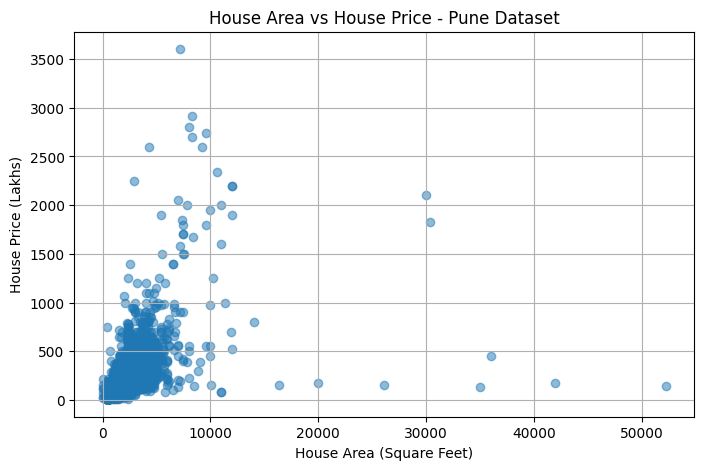

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["total_sqft"],
    df_clean["price"],
    alpha=0.5
)

plt.xlabel("House Area (Square Feet)")
plt.ylabel("House Price (Lakhs)")
plt.title("House Area vs House Price - Pune Dataset")
plt.grid(True)

plt.show()

Step 6: Split the dataset (80:20)
We will use:
- 80% Training data: To train the Linear Regression model.
- 20% Testing data: To evaluate the model on unseen data.

In [6]:
from sklearn.model_selection import train_test_split

# Select feature (X) and target (y)
X = df_clean[["total_sqft"]]
y = df_clean["price"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Total samples:", len(X))

Training samples: 10619
Testing samples: 2655
Total samples: 13274


Step 6: Train the Linear Regression model
Now we will train the model using the training dataset.

In [7]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


Step 8: Display the coefficient, intercept and regression equation
Now we will find the mathematical equation used by our model.

In [8]:
# Get coefficient and intercept
coefficient = model.coef_[0]
intercept = model.intercept_

print("Coefficient:", coefficient)
print("Intercept:", intercept)

print("\nLinear Regression Equation:")
print(f"Price = {intercept:.4f} + ({coefficient:.4f} × House Area)")

Coefficient: 0.0611168583274051
Intercept: 16.03897899604513

Linear Regression Equation:
Price = 16.0390 + (0.0611 × House Area)


Step 11: Make predictions on test data

In [9]:
# Predict house prices using test data
y_pred = model.predict(X_test)

# Compare actual and predicted prices
results = pd.DataFrame({
    "House Area (sq.ft.)": X_test["total_sqft"].values,
    "Actual Price (Lakhs)": y_test.values,
    "Predicted Price (Lakhs)": y_pred
})

display(results.head(10))

,House Area (sq.ft.),Actual Price (Lakhs),Predicted Price (Lakhs)
0,1800.0,85.00,126.049324
1,1600.0,160.00,113.825952
2,1125.0,65.00,84.795445
3,1920.0,150.00,133.383347
4,1715.0,100.00,120.854391
5,1320.0,55.44,96.713232
6,1500.0,140.00,107.714266
7,1090.0,46.00,82.656355
8,1063.0,58.00,81.006199
9,957.0,47.00,74.527812


Step 12: Evaluate model performance
Now we will calculate four important evaluation metrics:
- MAE: Mean Absolute Error.
- MSE: Mean Squared Error.
- RMSE: Root Mean Squared Error.
- R² Score: Measures how well the model explains price variation.


In [10]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 52.912863811943275
MSE: 18267.968569927307
RMSE: 135.15904916034037
R2 Score: 0.39809739068780625


Step 13: Actual vs Predicted Price Graph

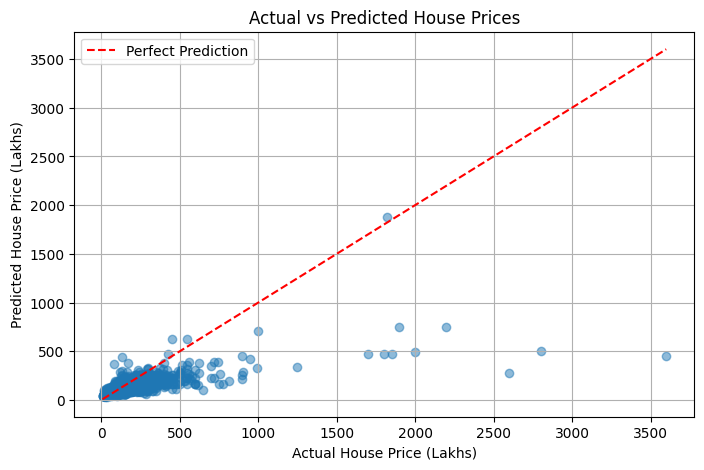

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label="Perfect Prediction"
)

plt.xlabel("Actual House Price (Lakhs)")
plt.ylabel("Predicted House Price (Lakhs)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True)

plt.show()

Step 14: Predict the price of a new house
Now we will test your model with a new house area.

In [12]:
# Enter a new house area in square feet
new_area = 1000

# Predict the house price
new_prediction = model.predict(pd.DataFrame({
    "total_sqft": [new_area]
}))

print("New House Area:", new_area, "sq.ft.")
print("Predicted House Price:", round(new_prediction[0], 2), "Lakhs")

New House Area: 1000 sq.ft.
Predicted House Price: 77.16 Lakhs


## Conclusion

In this activity, I implemented a Simple House Price Prediction model using **Linear Regression** and a Pune house price dataset.

The dataset was inspected and cleaned by handling missing and invalid values. I selected `total_sqft` as the independent feature (X) and `price` as the dependent target (y).

The dataset was divided into 80% training data and 20% testing data. A Linear Regression model was trained and evaluated using MAE, MSE, RMSE and R² Score. I also created scatter plots to understand the relationship between house area and price and to compare actual and predicted prices.

Finally, the trained model was used to predict the price of a new house based on its area.

### Limitations

1. The model uses only house area to predict price.
2. Location, number of bedrooms, amenities and property condition are not considered.
3. The predictions are estimates and may differ from actual market prices.
4. Linear Regression assumes a linear relationship between area and price.|